# Faster R-CNN untuk Deteksi Kematangan Buah Sawit

Notebook ini mendokumentasikan konfigurasi, pelatihan, validasi, evaluasi, dan fine-tuning Faster R-CNN ResNet-50-FPN untuk mendeteksi empat tingkat kematangan tandan buah sawit. Gambar diperoleh dari Roboflow, sedangkan anotasi COCO hasil preprocessing digunakan sebagai *ground truth*.

Evaluasi menggunakan COCO mAP@[0.50:0.95], mAP@0.50, dan mAP@0.75. Pemilihan checkpoint didasarkan pada split validasi; split test digunakan untuk evaluasi akhir.

## Tahap 1 — Instalasi Dependensi

Tahap ini memasang `roboflow` untuk akuisisi dataset dan `pycocotools` untuk perhitungan metrik COCO. PyTorch dan torchvision disediakan oleh lingkungan Kaggle.

In [1]:
!pip install -q roboflow pycocotools

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## Tahap 2 — Inisialisasi Library dan Perangkat Komputasi

Tahap ini memuat library, menetapkan seed acak untuk reproduktibilitas, dan memilih perangkat komputasi. GPU CUDA digunakan bila tersedia; CPU digunakan sebagai alternatif.

In [2]:
import json
import random
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torchvision
from PIL import Image, ImageEnhance
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__}')
print(f'torchvision: {torchvision.__version__}')
print(f'Device: {DEVICE}')

PyTorch: 2.11.0+cu128
torchvision: 0.26.0+cu128
Device: cuda


Nilai Device: cuda menunjukkan bahwa pelatihan menggunakan akselerasi GPU. Nilai cpu menunjukkan bahwa lingkungan eksekusi belum menggunakan GPU.

## Tahap 3 — Dataset dari Roboflow

Dataset format COCO diunduh ke direktori kerja Kaggle melalui Roboflow API. Kunci API disimpan sebagai Kaggle Secret bernama `ROBOFLOW_API_KEY`. Tahap ini memerlukan koneksi Internet.

In [3]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

ROBOFLOW_API_KEY = UserSecretsClient().get_secret('ROBOFLOW_API_KEY')
if not ROBOFLOW_API_KEY:
    raise ValueError('Buat Kaggle Secret bernama ROBOFLOW_API_KEY terlebih dahulu.')

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace('zah').project('palm-oil-fg85a')
version = project.version(3)
dataset = version.download('coco', location='/kaggle/working/palm-oil-coco')
IMAGE_DATASET_ROOT = Path(dataset.location)
print(f'Dataset tersimpan di: {IMAGE_DATASET_ROOT}')

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/palm-oil-coco in coco:: 100%|██████████| 8404/8404 [00:01<00:00, 5413.62it/s]


Dataset tersimpan di: /kaggle/working/palm-oil-coco


Output menegaskan lokasi unduhan serta ketersediaan folder train, valid, dan test. Berkas gambar pada lokasi tersebut dipasangkan dengan anotasi hasil preprocessing.

## Tahap 4 — Penetapan Anotasi dan Split Dataset

Berkas `instances_train.json`, `instances_val.json`, dan `instances_test.json` hasil preprocessing digunakan sebagai anotasi *ground truth*. Gambar train, validasi, dan test berasal dari ekspor Roboflow yang sama. Penyelarasan ini menjaga konsistensi objek, kelas, dan split dengan eksperimen YOLOv11.

In [5]:
USE_PREPROCESSED_ANNOTATIONS = True
PREPROCESSING_ROOT = Path('/kaggle/input/datasets/morenoadryan/palm-oil-preprocessing-output')

if USE_PREPROCESSED_ANNOTATIONS and not PREPROCESSING_ROOT.is_dir():
    raise FileNotFoundError('Tambahkan folder palm_oil_preprocessing_output ke Kaggle Input atau set USE_PREPROCESSED_ANNOTATIONS = False.')

annotation_files = {
    'train': (PREPROCESSING_ROOT / 'instances_train.json') if USE_PREPROCESSED_ANNOTATIONS else (IMAGE_DATASET_ROOT / 'train' / '_annotations.coco.json'),
    'val': (PREPROCESSING_ROOT / 'instances_val.json') if USE_PREPROCESSED_ANNOTATIONS else (IMAGE_DATASET_ROOT / 'valid' / '_annotations.coco.json'),
    'test': (PREPROCESSING_ROOT / 'instances_test.json') if USE_PREPROCESSED_ANNOTATIONS else (IMAGE_DATASET_ROOT / 'test' / '_annotations.coco.json'),
}
SPLITS = {
    'train': {'image_dir': IMAGE_DATASET_ROOT / 'train', 'annotation': annotation_files['train']},
    'val': {'image_dir': IMAGE_DATASET_ROOT / 'valid', 'annotation': annotation_files['val']},
    'test': {'image_dir': IMAGE_DATASET_ROOT / 'test', 'annotation': annotation_files['test']},
}
print('Sumber anotasi:', 'preprocessing output' if USE_PREPROCESSED_ANNOTATIONS else 'COCO Roboflow')
for split, paths in SPLITS.items():
    print(f"{split:5} | image_dir={paths['image_dir'].is_dir()} | annotation={paths['annotation'].is_file()}")

Sumber anotasi: preprocessing output
train | image_dir=True | annotation=True
val   | image_dir=True | annotation=True
test  | image_dir=True | annotation=True


Nilai image_dir exists=True dan annotation exists=True mengonfirmasi bahwa direktori gambar dan berkas anotasi tersedia. Nilai False menunjukkan ketidaksesuaian path atau nama folder input Kaggle.

## Tahap 5 — Definisi Kelas dan Konfigurasi Eksperimen

Model menghasilkan lima keluaran: background internal torchvision (ID 0) dan empat kelas kematangan (ID 1–4). Ukuran masukan ditetapkan 640×640 agar konsisten dengan preprocessing dan eksperimen YOLOv11. Hyperparameter pada tahap ini digunakan sebagai konfigurasi baseline.

In [6]:
CLASS_NAMES = {
    0: 'background',
    1: 'kurang masak',
    2: 'masak',
    3: 'mentah',
    4: 'terlalu masak',
}
NUM_CLASSES = len(CLASS_NAMES)  # background + 4 kelas sawit

@dataclass(frozen=True)
class Config:
    image_size: int = 640
    batch_size: int = 2
    num_workers: int = 2
    epochs: int = 20
    learning_rate: float = 0.005
    momentum: float = 0.9
    weight_decay: float = 0.0005
    lr_step_size: int = 10
    lr_gamma: float = 0.1
    score_threshold: float = 0.05

CFG = Config()
print(f'num_classes={NUM_CLASSES}, input={CFG.image_size}x{CFG.image_size}, batch_size={CFG.batch_size}')

num_classes=5, input=640x640, batch_size=2


Konfigurasi num_classes=5 merepresentasikan empat kelas kematangan dan satu kelas background internal Faster R-CNN. Ukuran masukan 640×640 digunakan sebagai acuan eksperimen.

## Tahap 6 — Validasi Integritas Dataset COCO

Tahap validasi memeriksa keberadaan direktori gambar dan anotasi, kesesuaian nama berkas gambar, serta urutan dan ID kategori. Proses ini memastikan anotasi preprocessing konsisten dengan gambar pada setiap split.

In [8]:
def load_and_validate_coco(split_name, image_dir, annotation_path):
    if not image_dir.is_dir():
        raise FileNotFoundError(f'Folder gambar {split_name} tidak ditemukan: {image_dir}')
    if not annotation_path.is_file():
        raise FileNotFoundError(f'JSON {split_name} tidak ditemukan: {annotation_path}')

    with annotation_path.open(encoding='utf-8') as f:
        coco = json.load(f)

    expected_categories = [
        {'id': class_id, 'name': class_name}
        for class_id, class_name in CLASS_NAMES.items() if class_id != 0
    ]
    # Ekspor COCO Roboflow menyimpan kategori ID 0 yang tidak dipakai anotasi.
    # Filter agar tidak tertukar dengan background internal Faster R-CNN.
    actual_categories = [{'id': c['id'], 'name': c['name']} for c in coco['categories'] if c['id'] != 0]
    if actual_categories != expected_categories:
        raise ValueError(f'Kategori {split_name} tidak cocok: {actual_categories}')

    missing = [item['file_name'] for item in coco['images'] if not (image_dir / item['file_name']).is_file()]
    if missing:
        raise FileNotFoundError(f'{len(missing)} gambar {split_name} hilang. Contoh: {missing[:3]}')

    print(f"{split_name:5} OK | {len(coco['images']):,} gambar | {len(coco['annotations']):,} anotasi")
    return coco

COCO = {
    split: load_and_validate_coco(split, paths['image_dir'], paths['annotation'])
    for split, paths in SPLITS.items()
}

train OK | 5,893 gambar | 9,266 anotasi
val   OK | 1,676 gambar | 2,654 anotasi
test  OK | 827 gambar | 1,355 anotasi


Jumlah gambar dan anotasi per split mendokumentasikan data yang digunakan dalam eksperimen. ID kategori 1–4 dan urutannya konsisten dengan konfigurasi kelas model.

## Tahap 7 — Dataset PyTorch dan Augmentasi Training

Dataset COCO dikonversi menjadi format target Faster R-CNN. Augmentasi online pada split train mencakup flip horizontal serta perubahan brightness dan contrast ringan. Split validasi dan test tidak menerima augmentasi. Normalisasi ImageNet ditangani oleh transform internal Faster R-CNN.

In [9]:
class PalmOilCocoDataset(Dataset):
    def __init__(self, image_dir, coco, train=False):
        self.image_dir = Path(image_dir)
        self.images = coco['images']
        self.train = train
        self.annotations_by_image = {}
        for ann in coco['annotations']:
            self.annotations_by_image.setdefault(ann['image_id'], []).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image = Image.open(self.image_dir / image_info['file_name']).convert('RGB')
        width, height = image.size
        anns = self.annotations_by_image.get(image_info['id'], [])

        boxes = [[x, y, x + w, y + h] for x, y, w, h in (ann['bbox'] for ann in anns)]
        labels = [ann['category_id'] for ann in anns]

        # Augmentasi online khusus train; ubah box saat gambar dibalik.
        if self.train and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            boxes = [[width - xmax, ymin, width - xmin, ymax] for xmin, ymin, xmax, ymax in boxes]
        if self.train:
            image = ImageEnhance.Brightness(image).enhance(random.uniform(0.9, 1.1))
            image = ImageEnhance.Contrast(image).enhance(random.uniform(0.9, 1.1))

        image_tensor = torchvision.transforms.functional.pil_to_tensor(image).float() / 255.0
        target = {
            'boxes': torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            'labels': torch.as_tensor(labels, dtype=torch.int64),
            'image_id': torch.tensor([image_info['id']]),
            'area': torch.as_tensor([ann['area'] for ann in anns], dtype=torch.float32),
            'iscrowd': torch.as_tensor([ann.get('iscrowd', 0) for ann in anns], dtype=torch.int64),
        }
        return image_tensor, target

def detection_collate_fn(batch):
    return tuple(zip(*batch))

## Tahap 8 — DataLoader dan Verifikasi Batch

DataLoader dibangun untuk split train, validasi, dan test menggunakan fungsi collate untuk deteksi objek. Pemeriksaan satu batch memverifikasi bentuk tensor gambar dan jumlah bounding box sebelum pelatihan dimulai.

In [10]:
datasets = {
    'train': PalmOilCocoDataset(SPLITS['train']['image_dir'], COCO['train'], train=True),
    'val': PalmOilCocoDataset(SPLITS['val']['image_dir'], COCO['val'], train=False),
    'test': PalmOilCocoDataset(SPLITS['test']['image_dir'], COCO['test'], train=False),
}

loaders = {
    split: DataLoader(
        dataset, batch_size=CFG.batch_size, shuffle=(split == 'train'),
        num_workers=CFG.num_workers, pin_memory=(DEVICE.type == 'cuda'),
        collate_fn=detection_collate_fn, persistent_workers=(CFG.num_workers > 0),
    )
    for split, dataset in datasets.items()
}

images, targets = next(iter(loaders['train']))
print(f'Batch train: {len(images)} gambar')
print(f'Ukuran gambar pertama: {tuple(images[0].shape)}')
print(f'Jumlah box gambar pertama: {len(targets[0]["boxes"])}')

Batch train: 2 gambar
Ukuran gambar pertama: (3, 640, 640)
Jumlah box gambar pertama: 1


Tensor gambar berukuran 3×640×640 serta target yang memuat bounding box dan label mengonfirmasi bahwa pipeline DataLoader untuk deteksi objek telah berfungsi dengan benar.

## Tahap 9 — Konstruksi Model Faster R-CNN

Arsitektur `fasterrcnn_resnet50_fpn` diinisialisasi menggunakan bobot pralatih COCO. Head prediksi diganti untuk menghasilkan lima keluaran. Parameter `min_size` dan `max_size` ditetapkan ke 640 agar skala masukan konsisten.

In [11]:
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights, fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

model = fasterrcnn_resnet50_fpn(
    weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
    min_size=CFG.image_size,
    max_size=CFG.image_size,
)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
model.to(DEVICE)

assert model.roi_heads.box_predictor.cls_score.out_features == NUM_CLASSES
print('Model berhasil dikonfigurasi.')
print(f'Head classifier output: {model.roi_heads.box_predictor.cls_score.out_features} kelas')
print(f'Ukuran transform model: min={model.transform.min_size}, max={model.transform.max_size}')

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 233MB/s] 


Model berhasil dikonfigurasi.
Head classifier output: 5 kelas
Ukuran transform model: min=(640,), max=640


Model menggunakan backbone ResNet-50-FPN dengan bobot pralatih COCO dan head prediksi untuk lima kelas. Bobot pralatih digunakan untuk mendukung konvergensi pelatihan.

## Tahap 10 — Inisialisasi Pelatihan dan Checkpoint

Tahap ini menetapkan optimizer SGD, scheduler StepLR, mixed precision, serta direktori keluaran. Checkpoint terakhir dan checkpoint terbaik disimpan secara terpisah. Checkpoint terbaik ditentukan berdasarkan mAP validasi; split test tidak digunakan selama pelatihan.

In [12]:
import time
from collections import defaultdict

import matplotlib.pyplot as plt
from pycocotools.coco import COCO as COCOApi
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm

if DEVICE.type != 'cuda':
    print('Peringatan: training Faster R-CNN 640x640 di CPU sangat lambat. Ganti accelerator ke GPU T4 lalu restart session sebelum training penuh.')

RUN_DIR = Path('/kaggle/working/faster_rcnn_sawit')
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = RUN_DIR / 'best_faster_rcnn_resnet50_fpn.pth'
LAST_CHECKPOINT = RUN_DIR / 'last_faster_rcnn_resnet50_fpn.pth'
HISTORY_PATH = RUN_DIR / 'history.json'

optimizer = torch.optim.SGD(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=CFG.learning_rate,
    momentum=CFG.momentum,
    weight_decay=CFG.weight_decay,
)
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=CFG.lr_step_size, gamma=CFG.lr_gamma
)
AMP_ENABLED = DEVICE.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)

print(f'Output training: {RUN_DIR}')
print(f'AMP aktif: {AMP_ENABLED}')

Output training: /kaggle/working/faster_rcnn_sawit
AMP aktif: True


Direktori /kaggle/working/faster_rcnn_sawit menjadi lokasi penyimpanan checkpoint terbaik, checkpoint terakhir, riwayat pelatihan, dan grafik baseline.

## Tahap 11 — Fungsi Pelatihan per Epoch dan Evaluasi COCO

Fungsi pelatihan menghitung loss deteksi, melakukan backpropagation, pembaruan bobot, dan gradient clipping. Fungsi evaluasi menghasilkan mAP@[0.50:0.95], mAP@0.50, dan mAP@0.75 menggunakan COCO API. mAP validasi digunakan sebagai dasar pemilihan checkpoint.

In [13]:
def move_targets_to_device(targets):
    return [{key: value.to(DEVICE) for key, value in target.items()} for target in targets]


def train_one_epoch(model, loader, optimizer, scaler, epoch):
    model.train()
    running_loss = 0.0
    progress = tqdm(loader, desc=f'Train {epoch}/{CFG.epochs}', leave=False)

    for images, targets in progress:
        images = [image.to(DEVICE, non_blocking=True) for image in images]
        targets = move_targets_to_device(targets)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
            loss_dict = model(images, targets)
            total_loss = sum(loss for loss in loss_dict.values())

        if not torch.isfinite(total_loss):
            raise RuntimeError(f'Loss tidak valid: {total_loss.item()}; hentikan dan cek anotasi/data.')

        scaler.scale(total_loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += total_loss.item()
        progress.set_postfix(loss=f'{total_loss.item():.4f}', lr=f'{optimizer.param_groups[0]["lr"]:.2e}')

    return running_loss / len(loader)


@torch.inference_mode()
def evaluate_coco(model, loader, annotation_path, split_name):
    model.eval()
    predictions = []
    image_ids = []
    progress = tqdm(loader, desc=f'Eval {split_name}', leave=False)

    for images, targets in progress:
        outputs = model([image.to(DEVICE, non_blocking=True) for image in images])
        for output, target in zip(outputs, targets):
            image_id = int(target['image_id'].item())
            image_ids.append(image_id)
            boxes = output['boxes'].detach().cpu().numpy()
            scores = output['scores'].detach().cpu().numpy()
            labels = output['labels'].detach().cpu().numpy()

            for box, score, label in zip(boxes, scores, labels):
                if score < CFG.score_threshold:
                    continue
                xmin, ymin, xmax, ymax = box.tolist()
                predictions.append({
                    'image_id': image_id,
                    'category_id': int(label),
                    'bbox': [xmin, ymin, xmax - xmin, ymax - ymin],
                    'score': float(score),
                })

    if not predictions:
        print(f'Tidak ada prediksi di atas score threshold untuk {split_name}.')
        return {'map': 0.0, 'map_50': 0.0, 'map_75': 0.0, 'num_predictions': 0}

    coco_gt = COCOApi(str(annotation_path))
    coco_dt = coco_gt.loadRes(predictions)
    coco_eval = COCOeval(coco_gt, coco_dt, iouType='bbox')
    coco_eval.params.imgIds = sorted(set(image_ids))
    coco_eval.params.catIds = list(CLASS_NAMES.keys())[1:]
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    return {
        'map': float(coco_eval.stats[0]),
        'map_50': float(coco_eval.stats[1]),
        'map_75': float(coco_eval.stats[2]),
        'num_predictions': len(predictions),
    }

## Tahap 12 — Pelatihan Baseline

Tahap ini melatih model hingga jumlah epoch yang ditetapkan pada konfigurasi baseline. Pada akhir setiap epoch, model dievaluasi pada split validasi dan checkpoint disimpan di `/kaggle/working/faster_rcnn_sawit/`. Split test tidak digunakan pada tahap ini.

In [12]:
history = defaultdict(list)
best_map = -float('inf')
training_start = time.time()

for epoch in range(1, CFG.epochs + 1):
    epoch_start = time.time()
    train_loss = train_one_epoch(model, loaders['train'], optimizer, scaler, epoch)
    val_metrics = evaluate_coco(model, loaders['val'], SPLITS['val']['annotation'], 'validasi')
    scheduler.step()

    epoch_record = {
        'epoch': epoch,
        'train_loss': float(train_loss),
        'val_map': float(val_metrics['map']),
        'val_map_50': float(val_metrics['map_50']),
        'val_map_75': float(val_metrics['map_75']),
        'learning_rate': float(optimizer.param_groups[0]['lr']),
        'epoch_seconds': float(time.time() - epoch_start),
    }
    for key, value in epoch_record.items():
        history[key].append(value)

    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'config': CFG.__dict__,
        'class_names': CLASS_NAMES,
        'val_metrics': val_metrics,
    }
    torch.save(checkpoint, LAST_CHECKPOINT)
    if val_metrics['map'] > best_map:
        best_map = val_metrics['map']
        torch.save(checkpoint, BEST_CHECKPOINT)
        status = ' <-- checkpoint terbaik'
    else:
        status = ''

    with HISTORY_PATH.open('w', encoding='utf-8') as file:
        json.dump(dict(history), file, indent=2)

    print(
        f"Epoch {epoch:02d}/{CFG.epochs} | loss={train_loss:.4f} | "
        f"val mAP={val_metrics['map']:.4f} | mAP50={val_metrics['map_50']:.4f} | "
        f"waktu={(time.time() - epoch_start) / 60:.1f} menit{status}"
    )

print(f'Training selesai dalam {(time.time() - training_start) / 60:.1f} menit.')
print(f'Checkpoint terbaik: {BEST_CHECKPOINT}')

Train 1/20:   0%|          | 0/2947 [00:00<?, ?it/s]

Eval validasi:   0%|          | 0/838 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.42s).
Accumulating evaluation results...
DONE (t=0.29s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.584
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.856
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.727
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.550
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.584
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.416
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.744
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Train 2/20:   0%|          | 0/2947 [00:00<?, ?it/s]

Eval validasi:   0%|          | 0/838 [00:00<?, ?it/s]

...

Eval validasi:   0%|          | 0/838 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.81s).
Accumulating evaluation results...
DONE (t=0.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.709
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.946
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.883
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.500
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.709
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.456
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.799
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Train 20/20:   0%|          | 0/2947 [00:00<?, ?it/s]

Eval validasi:   0%|          | 0/838 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.74s).
Accumulating evaluation results...
DONE (t=0.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.705
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.942
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.887
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.550
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.705
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.454
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.799
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Nilai loss dan val mAP dicatat pada setiap epoch. Penanda <-- checkpoint terbaik baru menunjukkan pembaruan checkpoint berdasarkan mAP validasi; checkpoint baseline terbaik diperoleh pada epoch 19 dengan mAP sekitar 0,7088.

## Tahap 13 — Visualisasi Learning Curve Baseline

Grafik menampilkan perubahan training loss, mAP@[0.50:0.95], dan mAP@0.50 pada setiap epoch. Visualisasi digunakan untuk mengamati konvergensi model dan indikasi plateau atau overfitting.

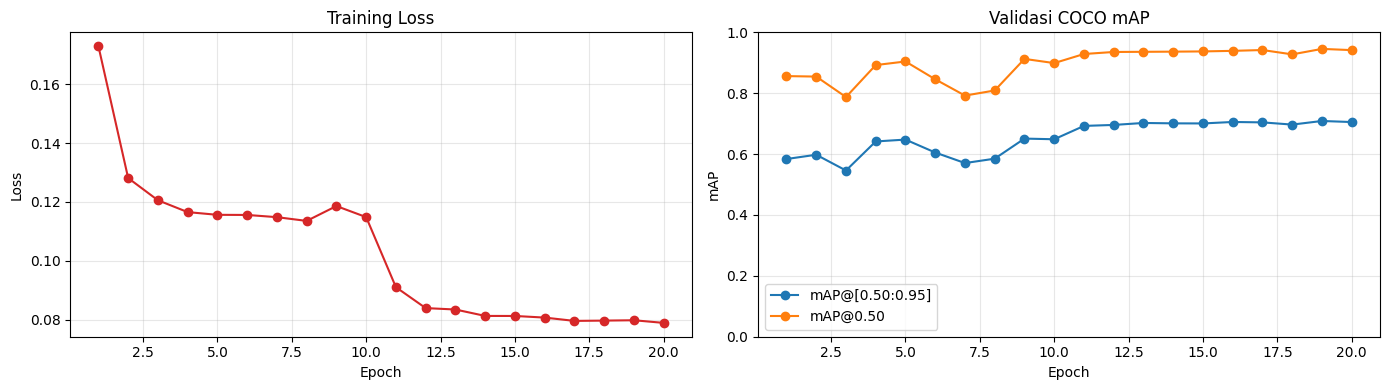

Grafik tersimpan: /kaggle/working/faster_rcnn_sawit/learning_curve.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
epochs = history['epoch']

axes[0].plot(epochs, history['train_loss'], marker='o', color='tab:red')
axes[0].set(title='Training Loss', xlabel='Epoch', ylabel='Loss')
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history['val_map'], marker='o', label='mAP@[0.50:0.95]')
axes[1].plot(epochs, history['val_map_50'], marker='o', label='mAP@0.50')
axes[1].set(title='Validasi COCO mAP', xlabel='Epoch', ylabel='mAP', ylim=(0, 1))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plot_path = RUN_DIR / 'learning_curve.png'
plt.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()
print(f'Grafik tersimpan: {plot_path}')

Penurunan loss yang disertai kenaikan dan stabilisasi mAP validasi menunjukkan konvergensi model. Meskipun epoch 20 tercatat dalam riwayat baseline, checkpoint terbaik berada pada epoch 19 karena memiliki mAP validasi lebih tinggi.

## Tahap 14 — Evaluasi Baseline pada Split Test

Checkpoint baseline dengan mAP validasi tertinggi dievaluasi pada split test. Metrik yang dihasilkan digunakan sebagai performa baseline untuk perbandingan terhadap hasil fine-tuning.

In [14]:
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Checkpoint terbaik belum tersedia: {BEST_CHECKPOINT}')

best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE, weights_only=False)
model.load_state_dict(best_checkpoint['model_state_dict'])
model.to(DEVICE)

test_metrics = evaluate_coco(model, loaders['test'], SPLITS['test']['annotation'], 'test')
results = {
    'best_epoch': best_checkpoint['epoch'],
    'best_validation_metrics': best_checkpoint['val_metrics'],
    'test_metrics': test_metrics,
}
with (RUN_DIR / 'final_metrics.json').open('w', encoding='utf-8') as file:
    json.dump(results, file, indent=2)

print(f"Best epoch: {results['best_epoch']}")
print(f"Test mAP@[0.50:0.95]: {test_metrics['map']:.4f}")
print(f"Test mAP@0.50: {test_metrics['map_50']:.4f}")
print(f"Test mAP@0.75: {test_metrics['map_75']:.4f}")
print(f"Hasil tersimpan: {RUN_DIR / 'final_metrics.json'}")

Eval test:   0%|          | 0/414 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.39s).
Accumulating evaluation results...
DONE (t=0.09s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.716
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.956
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.879
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.716
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.444
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.800
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

## Artefak Hasil Baseline

Tahap baseline menghasilkan checkpoint terbaik dan terakhir, riwayat pelatihan, grafik learning curve, serta metrik final. Artefak utama yang disimpan adalah `best_faster_rcnn_resnet50_fpn.pth`, `last_faster_rcnn_resnet50_fpn.pth`, `history.json`, `learning_curve.png`, dan `final_metrics.json`.

Evaluasi baseline pada split test menghasilkan mAP@[0.50:0.95] sebesar 0,7157, mAP@0.50 sebesar 0,9562, dan mAP@0.75 sebesar 0,8791. Metrik tersebut menjadi pembanding untuk hasil fine-tuning.

## Tahap 15 - Fine-tuning dan Seleksi Checkpoint

Fine-tuning melanjutkan pembelajaran dari checkpoint baseline dengan mAP validasi tertinggi, bukan dari bobot awal. Checkpoint sumber berasal dari output training baseline dan memuat bobot model terbaik pada epoch ke-19.

Optimizer SGD baru digunakan dengan learning rate `1e-4`, lebih kecil daripada baseline (`0,005`). Setiap epoch mencakup pembaruan bobot pada split train dan evaluasi pada split validasi. Checkpoint hanya disimpan apabila mAP@[0.50:0.95] validasi melampaui checkpoint terbaik sebelumnya.

Pelatihan dibatasi maksimum 10 epoch dan dihentikan lebih awal apabila mAP validasi tidak meningkat selama lima epoch berturut-turut. Split test tidak digunakan untuk memilih checkpoint.

In [14]:
# Fine-tune dari checkpoint terbaik training pertama.
from collections import defaultdict
from pycocotools.coco import COCO as COCOApi
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm

checkpoint_candidates = list(Path('/kaggle/input').rglob('best_faster_rcnn_resnet50_fpn.pth'))
if len(checkpoint_candidates) != 1:
    raise FileNotFoundError(f'Harus ada tepat satu checkpoint best di Input. Ditemukan: {checkpoint_candidates}')

BASELINE_CHECKPOINT = checkpoint_candidates[0]
baseline_checkpoint = torch.load(BASELINE_CHECKPOINT, map_location=DEVICE, weights_only=False)
model.load_state_dict(baseline_checkpoint['model_state_dict'])
model.to(DEVICE)

FINE_TUNE_EPOCHS, FINE_TUNE_LR, PATIENCE = 10, 1e-4, 5
FINE_TUNE_DIR = Path('/kaggle/working/faster_rcnn_sawit_finetune')
FINE_TUNE_DIR.mkdir(parents=True, exist_ok=True)
FINE_TUNE_BEST = FINE_TUNE_DIR / 'best_faster_rcnn_finetuned.pth'

# Optimizer baru; state optimizer lama sengaja tidak dilanjutkan.
optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=FINE_TUNE_LR, momentum=CFG.momentum, weight_decay=CFG.weight_decay)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
AMP_ENABLED = DEVICE.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))

history_finetune = defaultdict(list)
best_map = float(baseline_checkpoint['val_metrics']['map'])
no_improvement = 0
print(f"Checkpoint baseline epoch {baseline_checkpoint['epoch']}; val mAP={best_map:.4f}")

for epoch in range(1, FINE_TUNE_EPOCHS + 1):
    train_loss = train_one_epoch(model, loaders['train'], optimizer, scaler, epoch)
    val_metrics = evaluate_coco(model, loaders['val'], SPLITS['val']['annotation'], 'validasi fine-tune')
    scheduler.step()
    history_finetune['epoch'].append(epoch)
    history_finetune['train_loss'].append(float(train_loss))
    history_finetune['val_map'].append(float(val_metrics['map']))
    history_finetune['val_map_50'].append(float(val_metrics['map_50']))

    fine_tune_checkpoint = {'fine_tune_epoch': epoch, 'baseline_epoch': baseline_checkpoint['epoch'], 'model_state_dict': model.state_dict(), 'class_names': CLASS_NAMES, 'config': CFG.__dict__, 'val_metrics': val_metrics}
    if val_metrics['map'] > best_map:
        best_map, no_improvement = float(val_metrics['map']), 0
        torch.save(fine_tune_checkpoint, FINE_TUNE_BEST)
        status = ' <-- checkpoint terbaik baru'
    else:
        no_improvement += 1
        status = f' | tanpa perbaikan {no_improvement}/{PATIENCE}'
    print(f"Fine-tune {epoch:02d}/{FINE_TUNE_EPOCHS} | loss={train_loss:.4f} | val mAP={val_metrics['map']:.4f}{status}")
    if no_improvement >= PATIENCE:
        print('Early stopping: mAP validasi tidak membaik.')
        break

with (FINE_TUNE_DIR / 'history_finetune.json').open('w', encodi
                                                    ng='utf-8') as file:
    json.dump(dict(history_finetune), file, indent=2)
print(f'Fine-tuning selesai. Best validation mAP={best_map:.4f}')

Checkpoint baseline epoch 19; val mAP=0.7088


Train 1/20:   0%|          | 0/2947 [00:00<?, ?it/s]

Eval validasi fine-tune:   0%|          | 0/838 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.13s).
Accumulating evaluation results...
DONE (t=0.18s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.710
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.946
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.883
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.600
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.710
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.457
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.799
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Train 2/20:   0%|          | 0/2947 [00:00<?, ?it/s]

...

Eval validasi fine-tune:   0%|          | 0/838 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.99s).
Accumulating evaluation results...
DONE (t=0.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.715
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.948
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.889
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.650
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.715
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.458
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.802
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Train 10/20:   0%|          | 0/2947 [00:00<?, ?it/s]

Eval validasi fine-tune:   0%|          | 0/838 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.83s).
Accumulating evaluation results...
DONE (t=0.17s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.715
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.948
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.886
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.650
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.715
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.457
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.802
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Fine-tuning dimulai dari checkpoint baseline epoch 19. Checkpoint fine-tuning diperbarui hanya ketika mAP validasi meningkat; performa terbaik diperoleh pada epoch tambahan ke-9 atau epoch kumulatif ke-28.

## Tahap 16 - Evaluasi Akhir Model Fine-tuned

Checkpoint fine-tuning dengan mAP validasi tertinggi dievaluasi pada split test yang tidak terlibat dalam optimasi. Jika fine-tuning tidak melampaui performa validasi baseline, checkpoint baseline dipertahankan sebagai model akhir.

Metrik akhir yang dilaporkan adalah COCO mAP@[0.50:0.95] dan mAP@0.50. Hasil evaluasi disimpan sebagai `final_metrics_finetune.json` di direktori `/kaggle/working/faster_rcnn_sawit_finetune/`.

In [15]:
# Jalankan SEKALI setelah cell fine-tuning selesai.
if FINE_TUNE_BEST.is_file():
    final_checkpoint = torch.load(FINE_TUNE_BEST, map_location=DEVICE, weights_only=False)
    selected_model = 'fine-tuned'
else:
    final_checkpoint = baseline_checkpoint
    selected_model = 'baseline (fine-tuning tidak meningkatkan validasi)'
model.load_state_dict(final_checkpoint['model_state_dict'])
test_metrics = evaluate_coco(model, loaders['test'], SPLITS['test']['annotation'], 'test fine-tune')
results = {'selected_model': selected_model, 'best_validation_metrics': final_checkpoint['val_metrics'], 'test_metrics': test_metrics}
with (FINE_TUNE_DIR / 'final_metrics_finetune.json').open('w', encoding='utf-8') as file:
    json.dump(results, file, indent=2)
print(f'Model terpilih: {selected_model}')
print(f"Test mAP@[.50:.95]: {test_metrics['map']:.4f}")
print(f"Test mAP@.50: {test_metrics['map_50']:.4f}")
print(f'Output tersimpan: {FINE_TUNE_DIR}')

Eval test fine-tune:   0%|          | 0/414 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.41s).
Accumulating evaluation results...
DONE (t=0.09s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.719
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.956
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.891
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.719
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.446
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.803
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Model fine-tuned dipilih sebagai model akhir karena menghasilkan mAP@[0.50:0.95] sebesar 0,7200, mAP@0.50 sebesar 0,9565, dan mAP@0.75 sebesar 0,8910 pada split test. Metrik tersebut merupakan hasil akhir eksperimen.

## Tahap 17 - Visualisasi Perbandingan Baseline dan Fine-tuning

Grafik membandingkan training loss dan mAP validasi antara pelatihan baseline dan fine-tuning pada sumbu epoch kumulatif. Garis vertikal menunjukkan checkpoint baseline sebagai titik awal fine-tuning, sedangkan garis horizontal menunjukkan mAP validasi terbaik baseline.

Visualisasi digunakan untuk mendokumentasikan pengaruh fine-tuning terhadap konvergensi dan performa validasi. Berkas gambar disimpan sebagai `baseline_vs_finetune.png`.

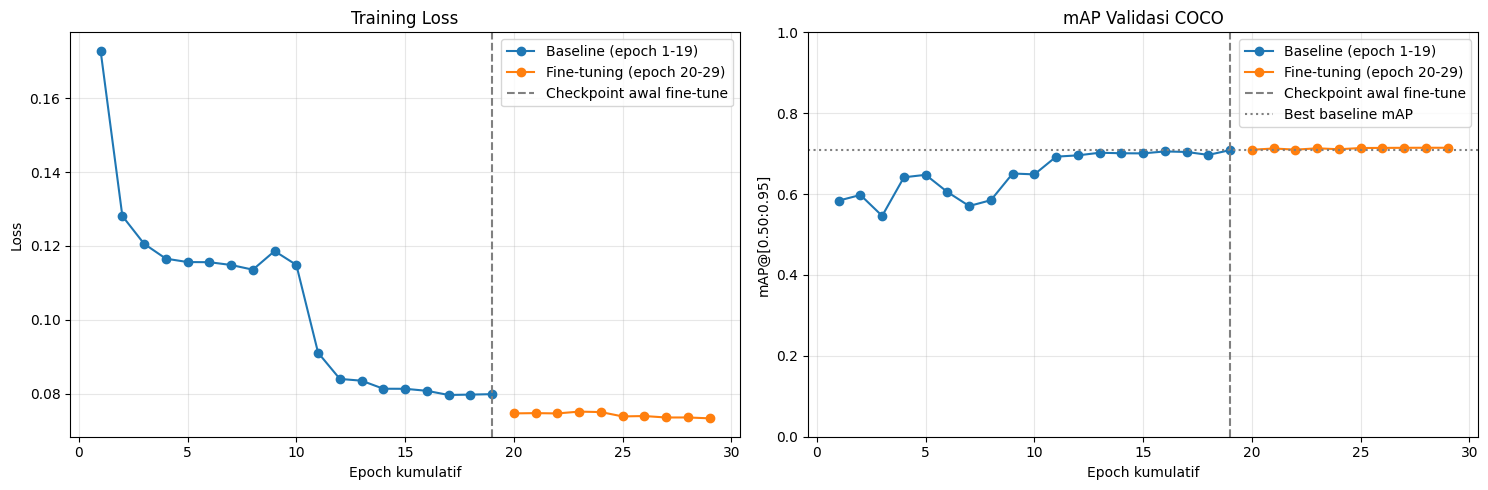

Visualisasi koreksi tersimpan: /kaggle/working/faster_rcnn_sawit_finetune/baseline_vs_finetune_corrected.png


In [17]:
# Visualisasi koreksi: baseline berhenti tepat pada checkpoint epoch 19.
base_epoch = baseline_checkpoint['epoch']
base_indices = [i for i, epoch in enumerate(history_baseline['epoch']) if epoch <= base_epoch]
base_epochs = [history_baseline['epoch'][i] for i in base_indices]
base_loss = [history_baseline['train_loss'][i] for i in base_indices]
base_map = [history_baseline['val_map'][i] for i in base_indices]
fine_epochs = [base_epoch + epoch for epoch in history_finetune['epoch']]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(base_epochs, base_loss, marker='o', label='Baseline (epoch 1-19)')
axes[0].plot(fine_epochs, history_finetune['train_loss'], marker='o', label='Fine-tuning (epoch 20-29)')
axes[0].axvline(base_epoch, color='gray', linestyle='--', label='Checkpoint awal fine-tune')
axes[0].set(title='Training Loss', xlabel='Epoch kumulatif', ylabel='Loss')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(base_epochs, base_map, marker='o', label='Baseline (epoch 1-19)')
axes[1].plot(fine_epochs, history_finetune['val_map'], marker='o', label='Fine-tuning (epoch 20-29)')
axes[1].axvline(base_epoch, color='gray', linestyle='--', label='Checkpoint awal fine-tune')
axes[1].axhline(baseline_checkpoint['val_metrics']['map'], color='gray', linestyle=':', label='Best baseline mAP')
axes[1].set(title='mAP Validasi COCO', xlabel='Epoch kumulatif', ylabel='mAP@[0.50:0.95]', ylim=(0, 1))
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
corrected_plot_path = FINE_TUNE_DIR / 'baseline_vs_finetune_corrected.png'
plt.savefig(corrected_plot_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Visualisasi koreksi tersimpan: {corrected_plot_path}')

Visualisasi tersebut merepresentasikan jalur pelatihan aktual: baseline hingga checkpoint epoch 19, kemudian fine-tuning pada epoch kumulatif 20–29. Peningkatan mAP validasi dari 0,7088 menjadi sekitar 0,7154 mendukung pemilihan checkpoint fine-tuned.

# **Analisis error pada data uji**
Bagian ini mengaudit prediksi fine-tuned pada data uji dengan IoU ≥ 0,50 dan ambang skor 0,50.
- Tandan terlewat: GT tidak mempunyai prediksi kelas yang sama pada IoU ≥ 0,50.
- Salah kelas: ada prediksi yang menutupi GT (IoU ≥ 0,50), tetapi label kelasnya berbeda.
- Box ganda: lebih dari satu prediksi kelas yang sama menutupi GT pada IoU ≥ 0,50; satu saja dihitung sebagai pasangan utama.
Output akan tersimpan di faster_rcnn_sawit_finetune/error_analysis/: ringkasan CSV, daftar semua error, dan tiga panel contoh. Kolom occlusion_review sengaja diisi manual setelah melihat gambar—tingkat keterhalangan daun tidak dapat disimpulkan secara andal hanya dari anotasi kotak.

Analisis error test:   0%|          | 0/827 [00:00<?, ?it/s]

Jumlah error: {'salah_kelas': 40, 'tandan_terlewat': 9, 'box_ganda': 1}
Miss menurut luminans: [{'kelompok_luminans': 'gelap', 'jumlah_gt': 921, 'terlewat': 34, 'rasio_terlewat': 0.037}, {'kelompok_luminans': 'sedang', 'jumlah_gt': 0, 'terlewat': 0, 'rasio_terlewat': nan}, {'kelompok_luminans': 'terang', 'jumlah_gt': 434, 'terlewat': 15, 'rasio_terlewat': 0.035}]


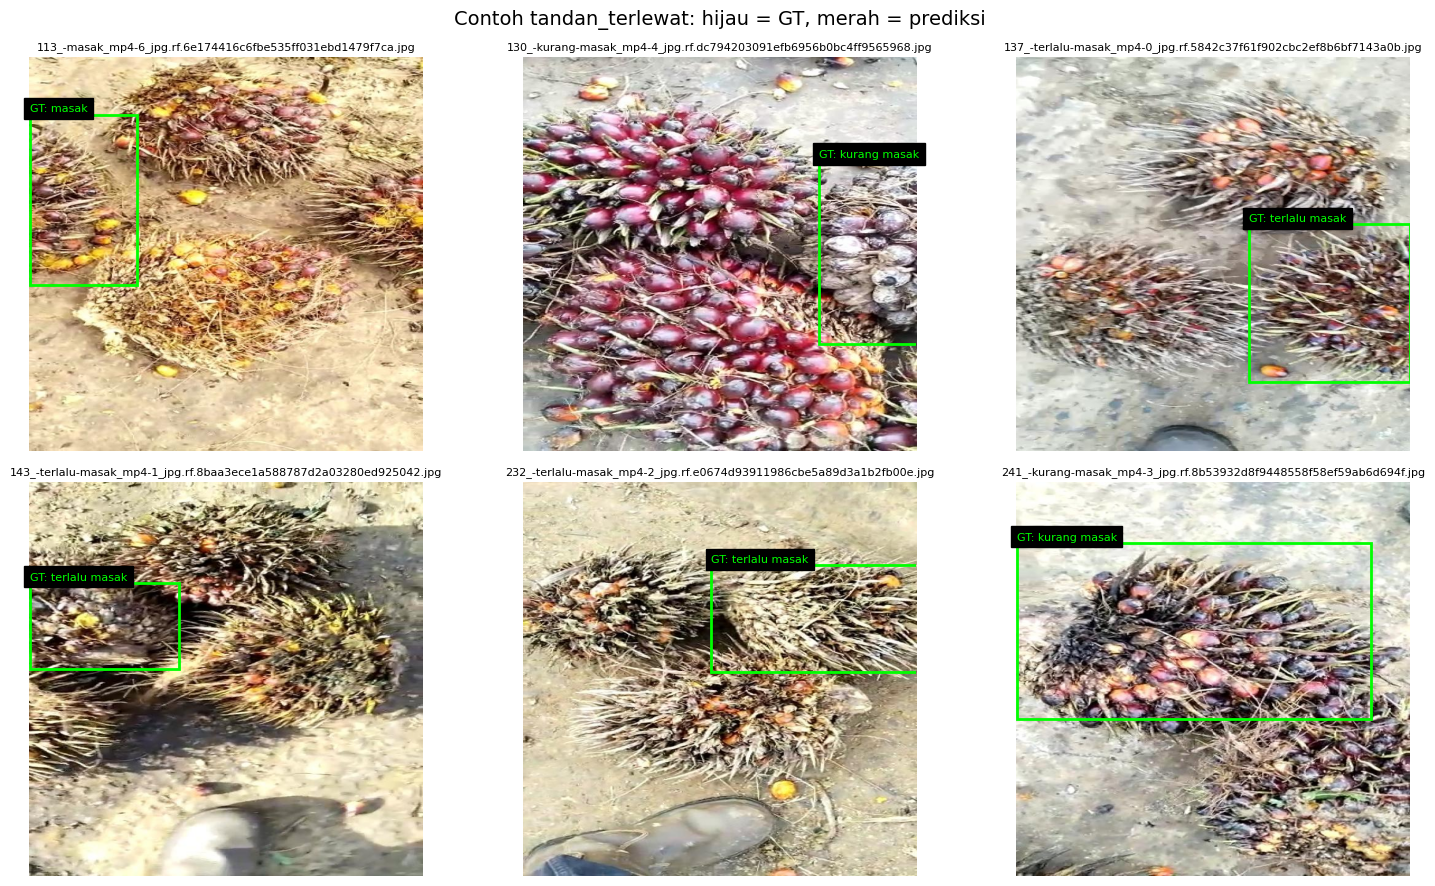

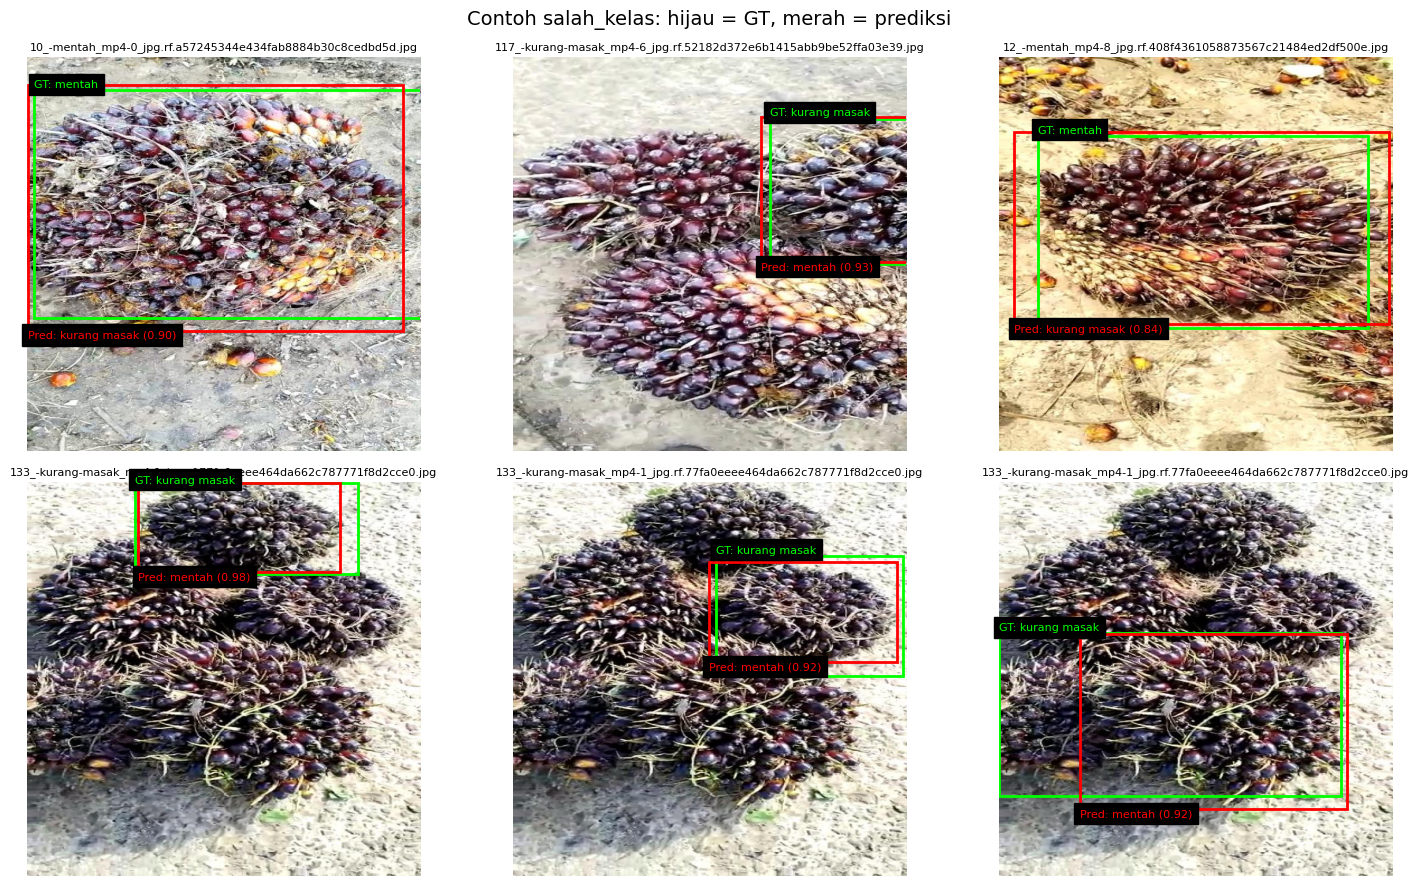

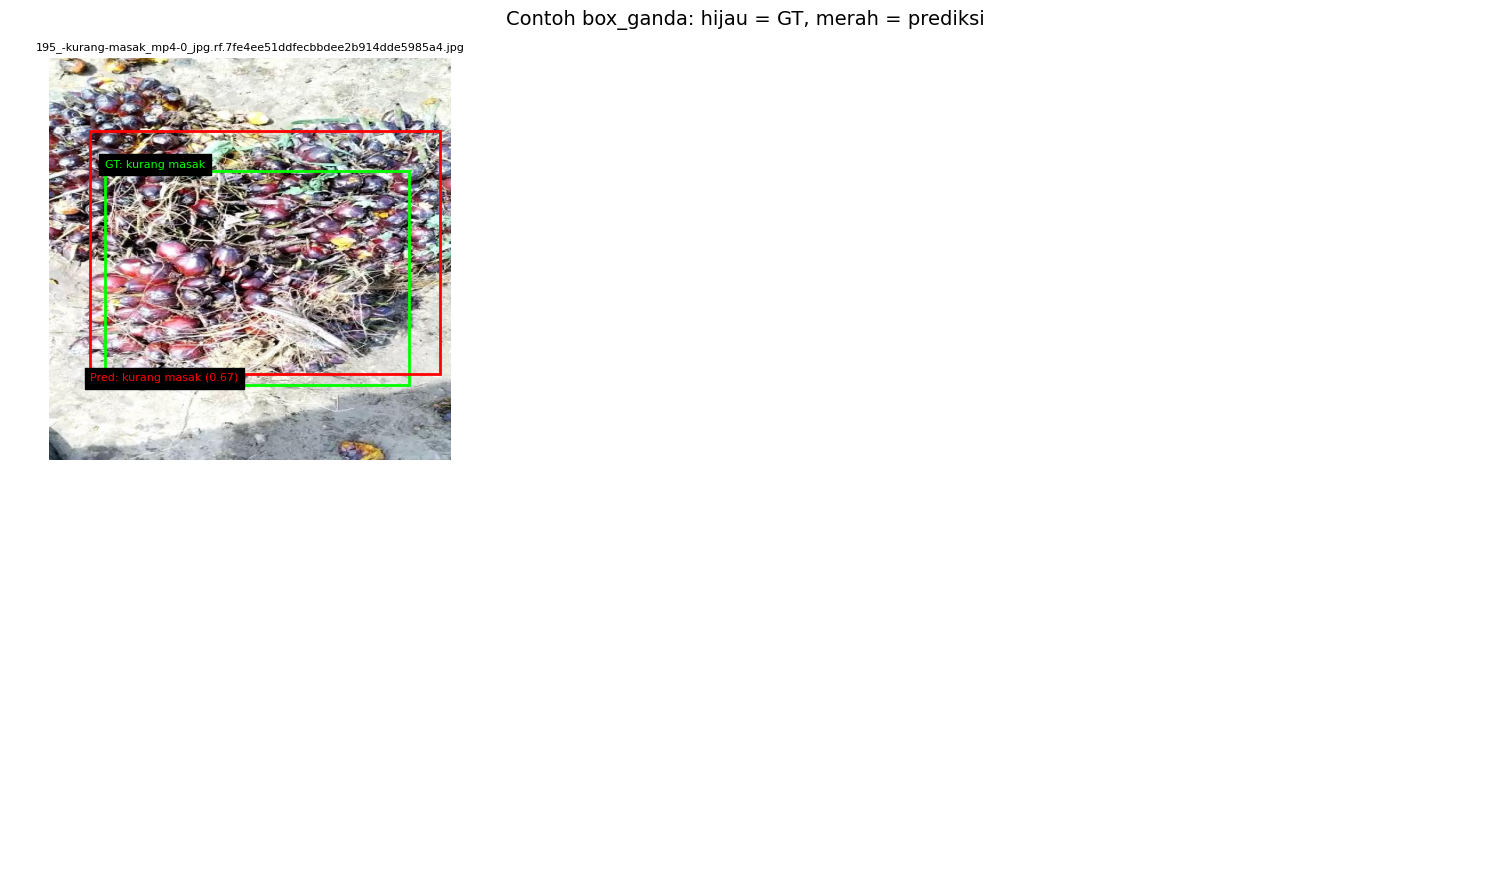

Analisis tersimpan di: /kaggle/working/faster_rcnn_sawit_finetune/error_analysis


In [23]:
# Analisis error: jalankan setelah cell evaluasi model fine-tuned (cell 45).
from collections import Counter
import csv

import matplotlib.patches as patches

ERROR_IOU = 0.50
ERROR_SCORE = 0.50
ERROR_DIR = FINE_TUNE_DIR / 'error_analysis'
ERROR_DIR.mkdir(parents=True, exist_ok=True)

def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = max(0, a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union else 0.0

def luminance(image_np, box):
    h, w = image_np.shape[:2]
    x1, y1, x2, y2 = np.clip(np.round(box).astype(int), [0, 0, 0, 0], [w, h, w, h])
    crop = image_np[y1:y2, x1:x2]
    return float(crop.mean()) if crop.size else float('nan')

@torch.inference_mode()
def collect_test_errors(model, dataset):
    model.eval()
    errors, all_gt, visual_cases = [], [], []
    for index in tqdm(range(len(dataset)), desc='Analisis error test'):
        image_tensor, target = dataset[index]
        output = model([image_tensor.to(DEVICE)])[0]
        image_np = image_tensor.permute(1, 2, 0).numpy()
        gt_boxes = target['boxes'].numpy()
        gt_labels = target['labels'].numpy()
        pred = [
            {'box': box.cpu().numpy(), 'label': int(label), 'score': float(score)}
            for box, label, score in zip(output['boxes'], output['labels'], output['scores'])
            if float(score) >= ERROR_SCORE
        ]
        image_id = int(target['image_id'].item())
        filename = dataset.images[index]['file_name']

        for gt_box, gt_label in zip(gt_boxes, gt_labels):
            overlaps = [(p, box_iou(gt_box, p['box'])) for p in pred]
            same = [(p, iou) for p, iou in overlaps if p['label'] == int(gt_label) and iou >= ERROR_IOU]
            wrong = [(p, iou) for p, iou in overlaps if p['label'] != int(gt_label) and iou >= ERROR_IOU]
            base = {
                'image_id': image_id, 'file_name': filename,
                'gt_class': CLASS_NAMES[int(gt_label)],
                'gt_box': [round(float(v), 1) for v in gt_box],
                'luminance': round(luminance(image_np, gt_box), 1),
                'occlusion_review': '',  # isi: none / partial / heavy setelah inspeksi panel
            }
            all_gt.append({**base, 'detected': bool(same)})
            if not same:
                kind = 'salah_kelas' if wrong else 'tandan_terlewat'
                best = max(wrong, key=lambda x: x[1]) if wrong else (None, 0.0)
                errors.append({**base, 'error_type': kind,
                               'pred_class': CLASS_NAMES[best[0]['label']] if best[0] else '',
                               'pred_score': round(best[0]['score'], 3) if best[0] else '',
                               'iou': round(best[1], 3)})
                visual_cases.append((kind, image_np, gt_box, int(gt_label), best[0] if best[0] else None, filename))
            elif len(same) > 1:
                for duplicate, iou in sorted(same, key=lambda x: x[0]['score'], reverse=True)[1:]:
                    errors.append({**base, 'error_type': 'box_ganda',
                                   'pred_class': CLASS_NAMES[duplicate['label']],
                                   'pred_score': round(duplicate['score'], 3), 'iou': round(iou, 3)})
                    visual_cases.append(('box_ganda', image_np, gt_box, int(gt_label), duplicate, filename))
    return errors, all_gt, visual_cases

errors, all_gt, visual_cases = collect_test_errors(model, datasets['test'])

fields = ['image_id', 'file_name', 'error_type', 'gt_class', 'pred_class', 'pred_score', 'iou', 'luminance', 'occlusion_review', 'gt_box']
with (ERROR_DIR / 'all_errors.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader(); writer.writerows(errors)

# Luminans dihitung dari area GT, lalu dibagi tertil agar ukuran grup cukup seimbang.
lum = np.array([r['luminance'] for r in all_gt])
q1, q2 = np.quantile(lum, [1/3, 2/3])
def light_bin(x): return 'gelap' if x <= q1 else ('sedang' if x <= q2 else 'terang')
summary = []
for label in ['gelap', 'sedang', 'terang']:
    subset = [r for r in all_gt if light_bin(r['luminance']) == label]
    missed = sum(not r['detected'] for r in subset)
    summary.append({'kelompok_luminans': label, 'jumlah_gt': len(subset), 'terlewat': missed,
                    'rasio_terlewat': round(missed / len(subset), 3) if subset else np.nan})
with (ERROR_DIR / 'miss_by_luminance.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=summary[0].keys())
    writer.writeheader(); writer.writerows(summary)

counts = Counter(row['error_type'] for row in errors)
print('Jumlah error:', dict(counts))
print('Miss menurut luminans:', summary)

def save_examples(kind, n=6):
    cases = [x for x in visual_cases if x[0] == kind][:n]
    if not cases:
        print(f'Tidak ada contoh {kind} pada ambang ini.'); return
    fig, axes = plt.subplots(2, 3, figsize=(15, 9)); axes = axes.ravel()
    for ax, (_, image, gt, gt_label, pred_item, filename) in zip(axes, cases):
        ax.imshow(image); ax.axis('off'); ax.set_title(filename, fontsize=8)
        ax.add_patch(patches.Rectangle((gt[0], gt[1]), gt[2]-gt[0], gt[3]-gt[1], fill=False, edgecolor='lime', linewidth=2))
        ax.text(gt[0], max(0, gt[1]-5), 'GT: ' + CLASS_NAMES[gt_label], color='lime', fontsize=8, backgroundcolor='black')
        if pred_item:
            p = pred_item['box']
            ax.add_patch(patches.Rectangle((p[0], p[1]), p[2]-p[0], p[3]-p[1], fill=False, edgecolor='red', linewidth=2))
            ax.text(p[0], p[3]+12, f"Pred: {CLASS_NAMES[pred_item['label']]} ({pred_item['score']:.2f})", color='red', fontsize=8, backgroundcolor='black')
    for ax in axes[len(cases):]: ax.axis('off')
    fig.suptitle(f'Contoh {kind}: hijau = GT, merah = prediksi', fontsize=14)
    fig.tight_layout()
    fig.savefig(ERROR_DIR / f'contoh_{kind}.png', dpi=180, bbox_inches='tight')
    plt.show()

for error_kind in ['tandan_terlewat', 'salah_kelas', 'box_ganda']:
    save_examples(error_kind)

print(f'Analisis tersimpan di: {ERROR_DIR}')


Berdasarkan analisis error pada data uji, model jarang menghasilkan box ganda dan sebagian besar lokasi tandan dapat ditemukan. Kesalahan dominan adalah salah klasifikasi kematangan, terutama pertukaran kelas mentah dan kurang masak. Bounding box prediksi pada banyak kasus sudah berada pada lokasi tandan yang tepat, tetapi kelasnya keliru dengan tingkat kepercayaan tinggi. Hal ini mengindikasikan adanya kemiripan visual antar kelas atau kemungkinan variasi/konsistensi anotasi pada dataset publik.  

Karena dataset berasal dari sumber publik Roboflow, perbaikan kualitas anotasi, penambahan contoh kondisi sulit, dan penegasan kriteria setiap tingkat kematangan merupakan rekomendasi untuk pengelola dataset. Dari sisi implementasi, model Faster R-CNN telah berhasil dilatih dan dievaluasi, namun performa klasifikasi masih bergantung pada kualitas serta representativitas data yang tersedia.